# LeWM: world models trained end-to-end from pixels, then used to plan

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/lewm.ipynb)

[LeWorldModel](https://arxiv.org/abs/2603.19312) ([code](https://github.com/lucas-maes/le-wm)) learns its encoder and predictor jointly from raw pixels, with no frozen backbone and no EMA target. Its loss has two terms: next-embedding prediction, and SIGReg, which keeps the embeddings Gaussian so they cannot collapse. A planner then searches for actions whose imagined future matches a goal image.

Two worlds, both simulated in [MuJoCo](https://mujoco.org) (`pip install torch-world[action]`):
1. a **Universal Robots UR10e** arm with a Robotiq 2F-85 gripper and a cube, after [OGBench](https://github.com/seohongpark/ogbench) `cube-single`;
2. **Push-T**, pushing a T-shaped block into a goal pose: the paper's benchmark, reproduced with the paper's model, data and evaluation protocol.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples,action]"

In [1]:
import itertools

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import PushT, RobotCube
from torch_world.models import LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM, RecedingHorizon
from torch_world.utils import recompute_batchnorm

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Part 1 · UR10e arm
### Play data
A noisy scripted policy picks the cube up and puts it down at random spots, like OGBench's `play` datasets. Actions move the gripper by up to 10 cm and open or close it, five times a second. Episodes are cut into windows of `history + 1` frames.

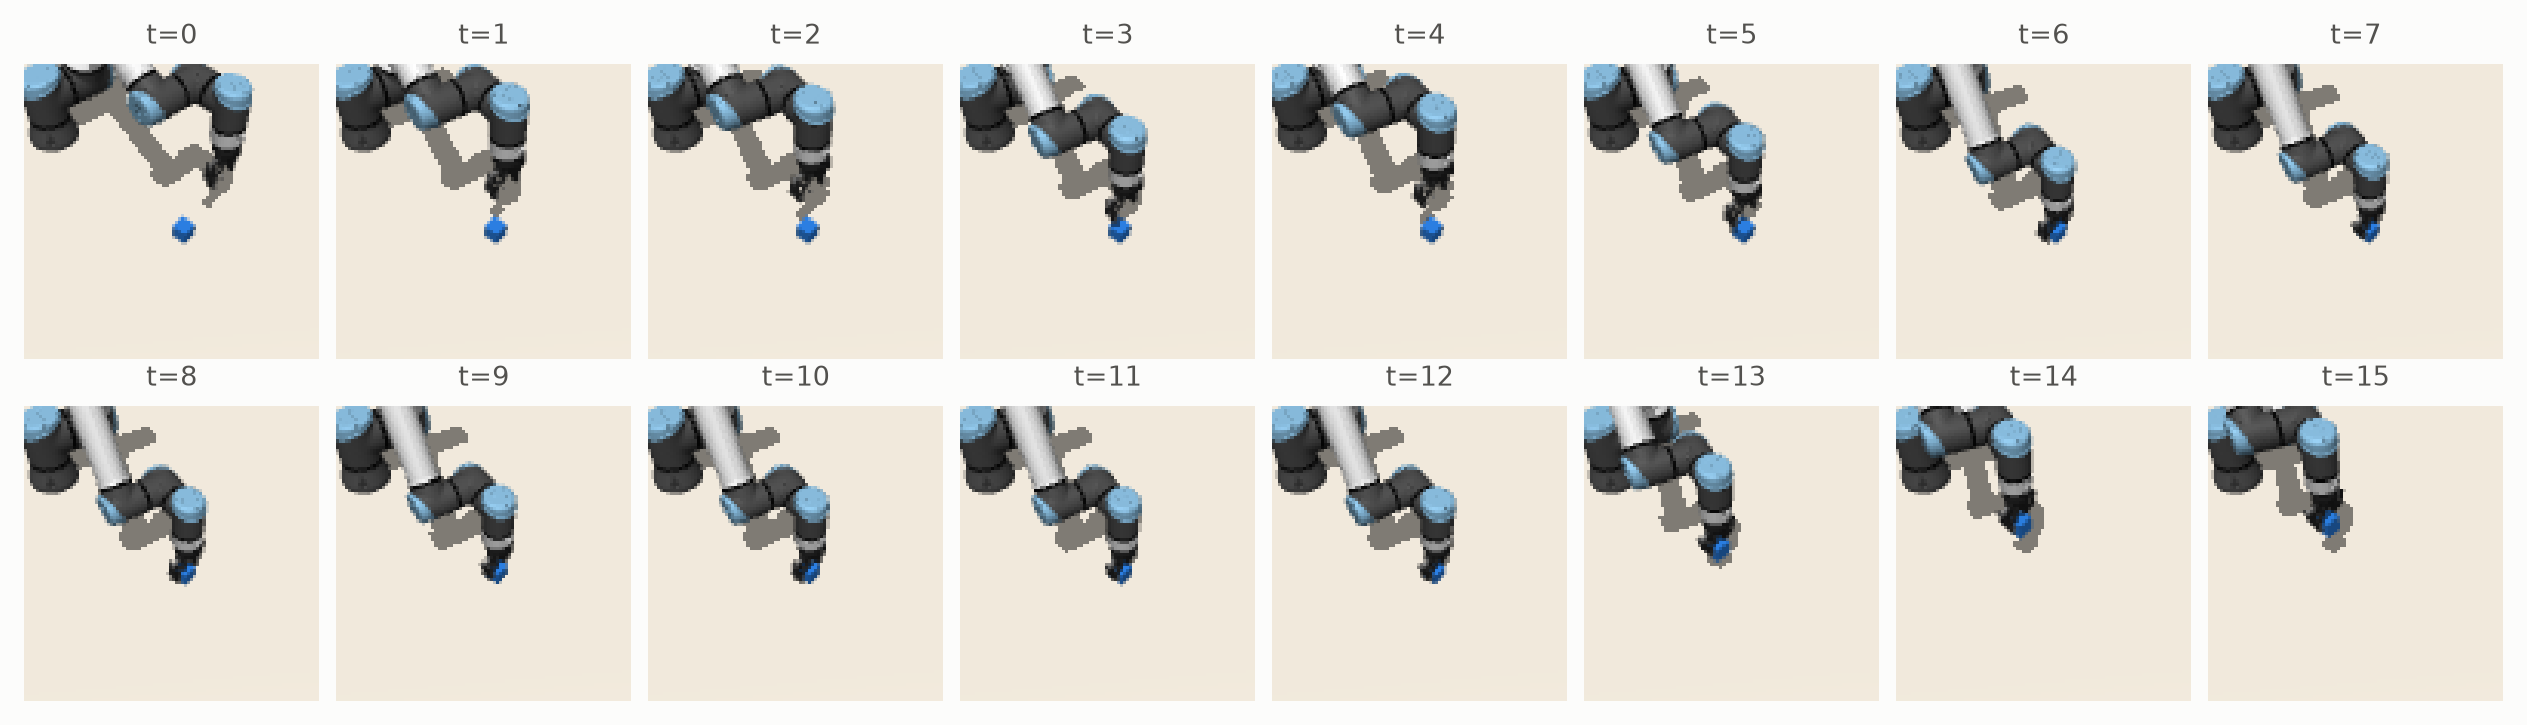

In [2]:
ROBOT = dict(robot="ur10e", size=96, control_dt=0.2, max_step=0.1)
HISTORY = 3
data = {k: v.to(device) for k, v in RobotCube(batch_size=1024, **ROBOT).collect(24, generator=torch.Generator().manual_seed(0)).items()}
loader = DataLoader(TrajectoryDataset(data, HISTORY + 1), batch_size=256, shuffle=True, drop_last=True)
plots.images(data["pixels"][2, :16].cpu(), [f"t={t}" for t in range(16)], size=1.3)

### Model and training
A small ViT whose CLS token embeds each frame, trained from scratch together with the predictor. The SIGReg weight is λ = 0.05.

7.79M parameters


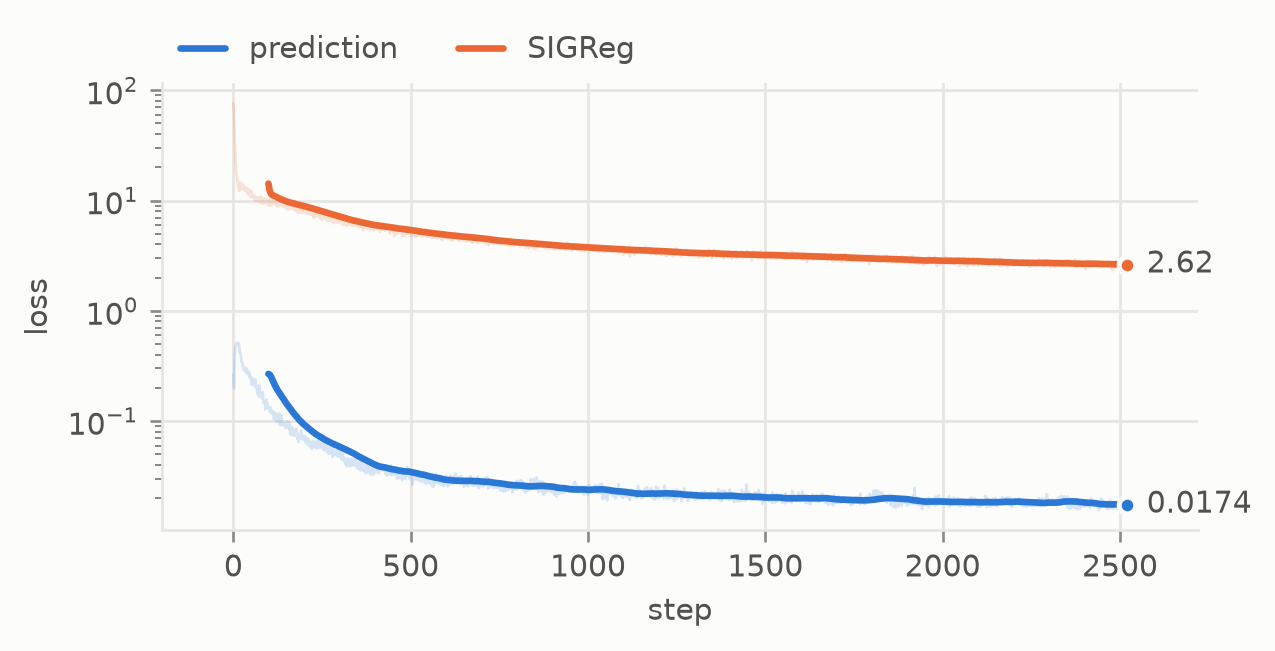

In [3]:
def train(model, loader, epochs, inputs):
    opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-3)
    log = {"prediction": [], "SIGReg": []}
    for epoch in range(epochs):
        for batch in loader:
            out = model(*inputs(batch))
            opt.zero_grad()
            out["loss"].backward()
            opt.step()
            log["prediction"].append(out["pred_loss"].item())
            log["SIGReg"].append(out["sigreg_loss"].item())
    recompute_batchnorm(model, itertools.islice(loader, 50), lambda b: model(*inputs(b)))
    return model.eval(), log


arm = LeWM(CLSEncoder(img_size=96, patch_size=12, embed_dim=192, depth=6, num_heads=6), action_dim=4, embed_dim=192, history=HISTORY, depth=6, num_heads=8, head_dim=32, mlp_dim=768, proj_dim=768, lamb=0.05).to(device)
print(f"{sum(p.numel() for p in arm.parameters()) / 1e6:.2f}M parameters")
arm, log = train(arm, loader, 30, lambda b: (b["pixels"], b["actions"]))
plots.curves(log, smooth=100)

### What the embedding knows
Three metrics from the papers, on held-out play data:
- **linear probes** (LeWM's physical probing): from frozen embeddings to the gripper and cube positions, fit on 4096 frames and scored by R² on 1024 others;
- **RankMe**: the effective rank of the embeddings, out of 192 dimensions; a collapsed encoder scores near 1;
- **open-loop prediction error**: from one real frame, the predictor unrolls the recorded actions, and each imagined embedding is compared with the encoding of the real frame. "Nothing changes" (repeating the first embedding) is the baseline.

linear probe R² 0.787   RankMe 64.2 / 192


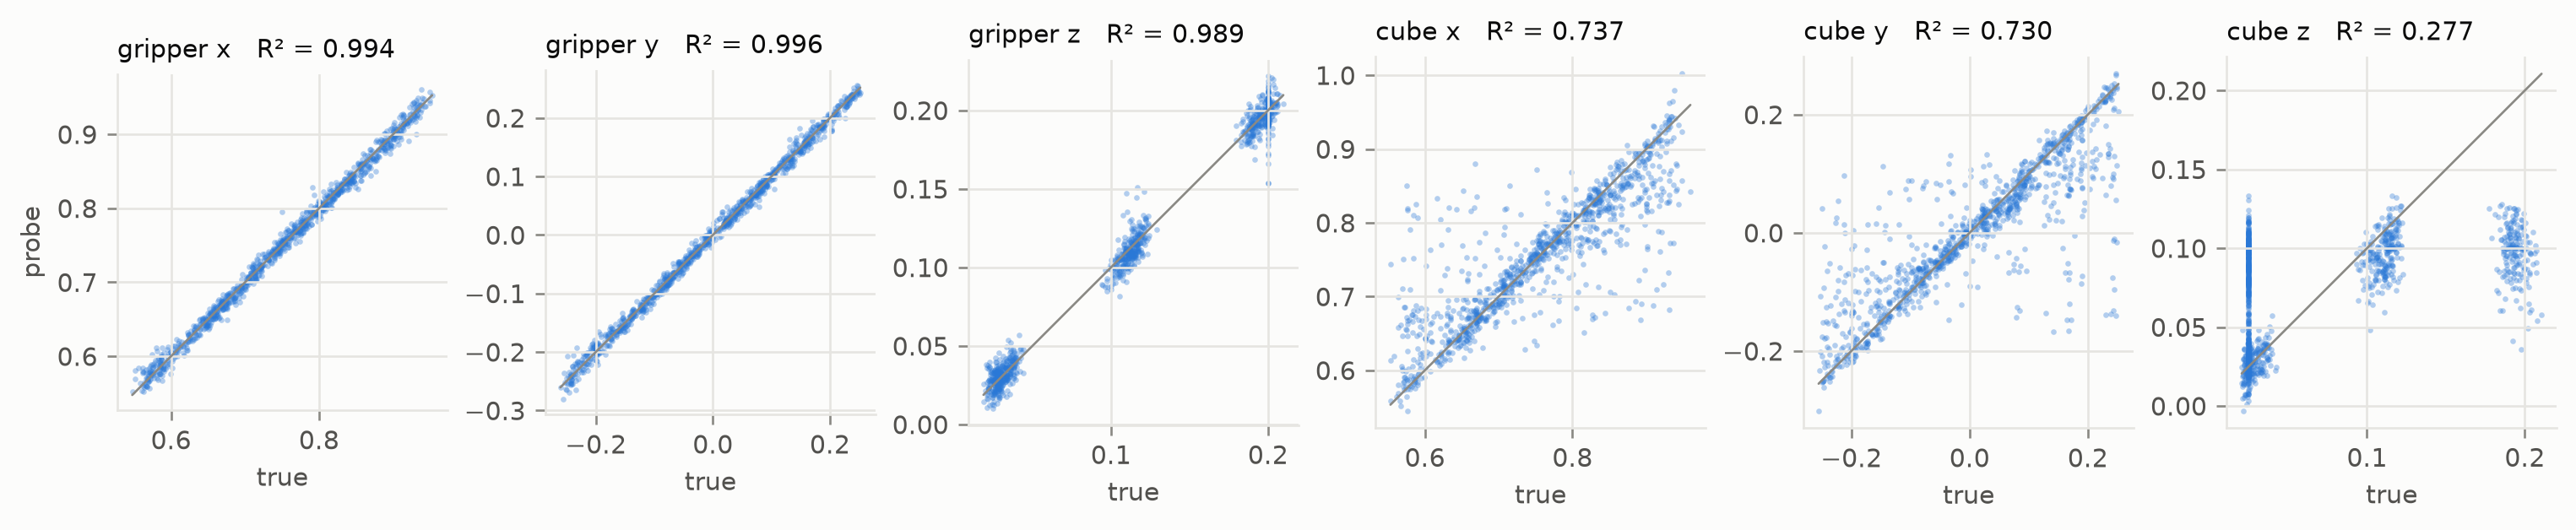

In [4]:
frames, states = data["pixels"][:, ::4].flatten(0, 1)[:5120], data["states"][:, ::4].flatten(0, 1)[:5120]
with torch.no_grad():
    z = torch.cat([arm.encode(f[:, None])[:, 0] for f in frames.split(1024)])
targets = {"gripper x": 0, "gripper y": 1, "gripper z": 2, "cube x": 4, "cube y": 5, "cube z": 6}
y = states[:, list(targets.values())]
probe = metrics.linear_probe(z[:4096], y[:4096], z[4096:], y[4096:])
print(f"linear probe R² {probe.score:.3f}   RankMe {metrics.rankme(z):.1f} / {z.size(1)}")
plots.probes(y[4096:], probe.predictions, list(targets), size=2.1)

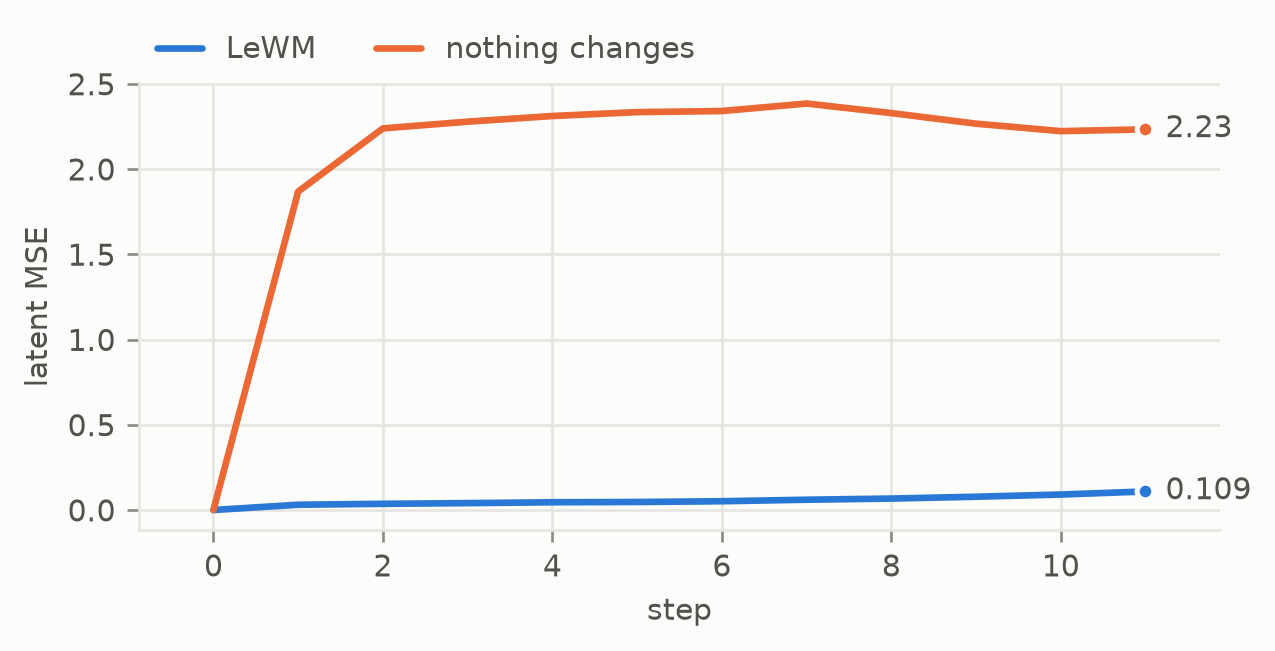

In [5]:
held_out = RobotCube(batch_size=128, **ROBOT).collect(12, generator=torch.Generator().manual_seed(5))
with torch.no_grad():
    real = torch.stack([arm.encode(held_out["pixels"][:, t : t + 1].to(device))[:, 0] for t in range(12)], 1)
    imagined = arm.rollout(real[:, :1], held_out["actions"][:, :11].to(device))
steps = range(12)
plots.curves({"LeWM": (steps, metrics.rollout_error(imagined, real, p=2).tolist()), "nothing changes": (steps, metrics.rollout_error(real[:, :1].expand_as(real), real, p=2).tolist())}, smooth=1, logy=False, ylabel="latent MSE")

### Plan toward goal images
Each task gives a start and the image of a goal state. CEM searches 5-step action sequences in latent space and MPC executes the first action of each plan. The `"path"` objective scores every imagined step, not only the last, so the planner moves now instead of postponing its moves to the end of the horizon.

Two tasks:
- **reach**: move the open gripper to the pose in the goal image; success within 5 cm.
- **pick and place**: carry the cube to the spot in the goal image (OGBench `cube-single`); success when the cube rests within 5 cm of it.

The scripted expert and random actions bracket the planner.

Each policy gets the standard measures of goal reaching: the final **success** rate with its 95% Wilson interval (16 episodes leave wide intervals), the share of episodes that **reached** the goal at any step and the mean **steps** to get there, the median **final distance** (meters), the median **progress** (fraction of the start distance closed), **SPL** (success weighted by how direct the path was), action **smoothness** (mean change between consecutive actions; lower is smoother) and the planning time per step.

== reach
                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM + CEM          75% [51%, 90%]      94%     3.4          0.0257     0.887   0.405       0.611    4.8e+03
scripted expert   100% [81%, 100%]     100%    2.56        6.01e-08         1   0.969       0.151      0.211
random actions        0% [0%, 19%]      12%       2            0.25    -0.102       0        1.55      0.174


== pick and place
                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM + CEM            0% [0%, 19%]       0%     nan           0.191         0       0       0.528   4.79e+03
scripted expert   100% [81%, 100%]     100%    12.1         0.00115     0.991   0.939       0.487      0.522
random actions        0% [0%, 19%]       0%     nan           0.191         0       0        1.56      0.165


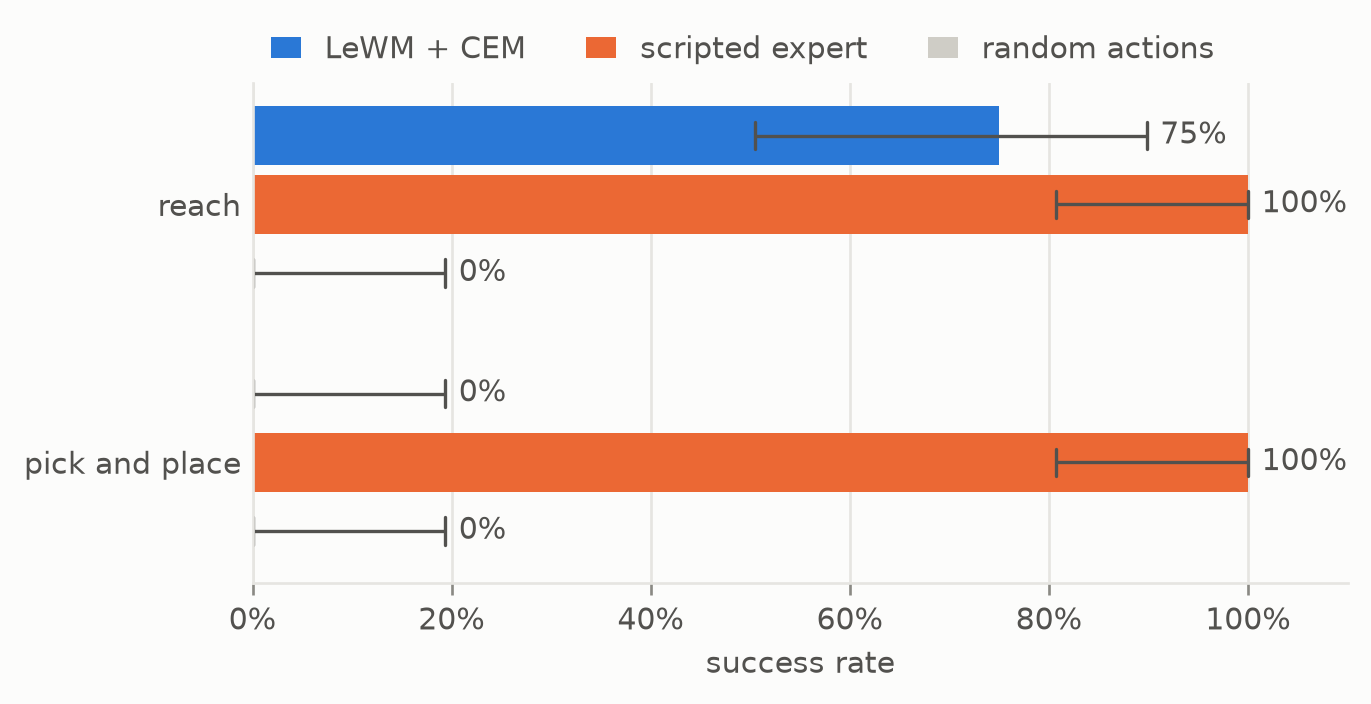

In [6]:
planner = CEM(horizon=5, action_dim=4, num_samples=256, num_elites=32, iterations=10, bounds=(-1, 1), objective="path")


def plan_with(model, goal_images):
    with torch.no_grad():
        goal = model.encode(goal_images[:, None].to(device))[:, 0]
    return lambda obs: planner(model, model.encode(obs[:, None].to(device)), goal)[:, 0].cpu()


arm_runs = {}
for task, steps in [("reach", 12), ("pick and place", 30)]:
    env = RobotCube(batch_size=16, task=task.split()[0], **ROBOT)
    start, goal_state = env.tasks(generator=torch.Generator().manual_seed(1))
    policies = {"LeWM + CEM": plan_with(arm, env.render(goal_state)), "scripted expert": lambda obs, env=env, goal_state=goal_state: env.scripted(goal_state), "random actions": evaluation.random_policy(env)}
    arm_runs[task] = evaluation.goal_reaching(env, policies, start, goal_state, steps, record=lambda e, goal_state=goal_state: e.render(size=160, goal=goal_state))
    print(f"== {task}\n{arm_runs[task]}")
plots.bars({task: r.intervals() for task, r in arm_runs.items()}, xlabel="success rate", baseline="random actions")

Reaching episodes of the planner. The translucent orange gripper marks the goal (videos only; the model sees the plain scene):


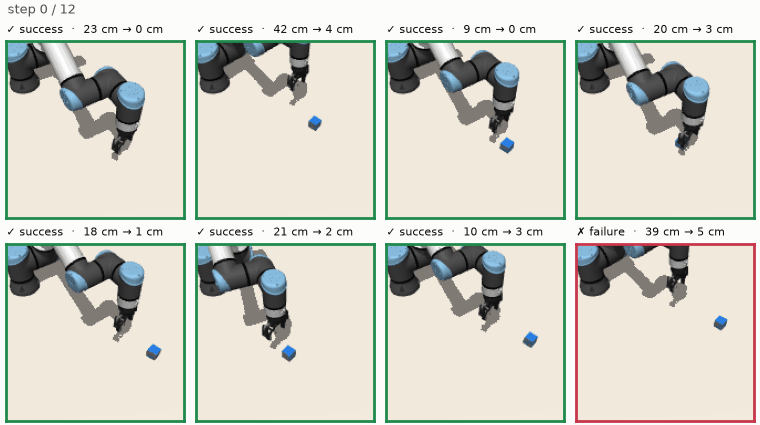

In [7]:
r = arm_runs["reach"]
plots.episodes(r.frames["LeWM + CEM"][:8], r.success["LeWM + CEM"][:8], [f"{100 * d:.0f} cm → {100 * e:.0f} cm" for d, e in r.distances["LeWM + CEM"][:8, [0, -1]].tolist()])

Pick and place is where greedy latent planning breaks down. The planner reaches the arm pose shown in the goal image, but carrying the cube needs a detour (descend, grasp, lift, carry) that a short horizon never finds attractive, and the cube is a small part of the image (see its weaker probes above). The paper reaches this task with far more data and longer horizons; here the expert and planner videos show the gap:


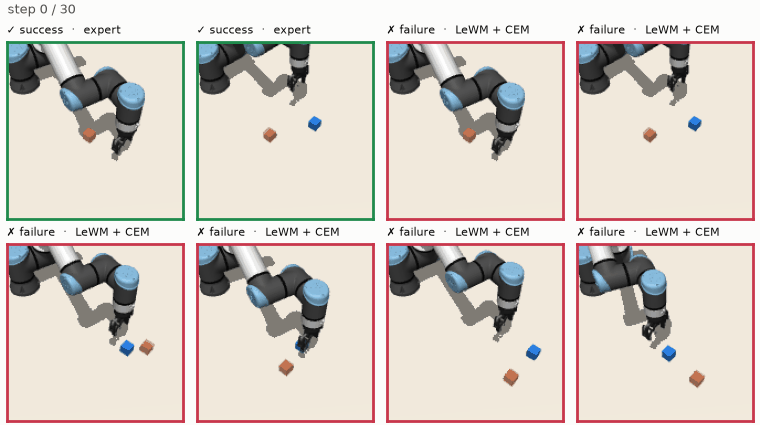

In [8]:
r = arm_runs["pick and place"]
plots.episodes(torch.cat([r.frames["scripted expert"][:2], r.frames["LeWM + CEM"][:6]]), torch.cat([r.success["scripted expert"][:2], r.success["LeWM + CEM"][:6]]), ["expert"] * 2 + ["LeWM + CEM"] * 6)

## Part 2 · Push-T, reproducing the paper
`PushT` follows the paper's Push-T (stable-worldmodel's `swm/PushT-v1`, simulated with pymunk) in MuJoCo, at the same scale (one reference pixel is one millimeter):
- the same arena, T block, round pusher and green target T;
- the same dynamics: an action moves the pusher's target up to 10 cm, a PD law drives the pusher toward it, contacts are frictionless, and the block stops as soon as it is no longer pushed;
- the same success test: pusher and block positions together within 2 cm of the goal's, and the T within 20° of its angle.

Replayed in this env from their recorded states, 98% of 25-step windows of the paper's expert actions end in the recorded state, against 99% in the reference simulator.

The model is the paper's (a 224 px ViT-tiny encoder and its predictor, 18M parameters), trained with the paper's recipe on the paper's 18,685 expert episodes replayed in this env. Training takes about 26 hours on one GPU, so it runs outside the notebook, which loads the checkpoint and the evaluation tasks from `checkpoints/` and evaluates it.

Tasks, as in the paper: each start is a state of an expert episode, and its goal the state the expert reached 25 steps later.

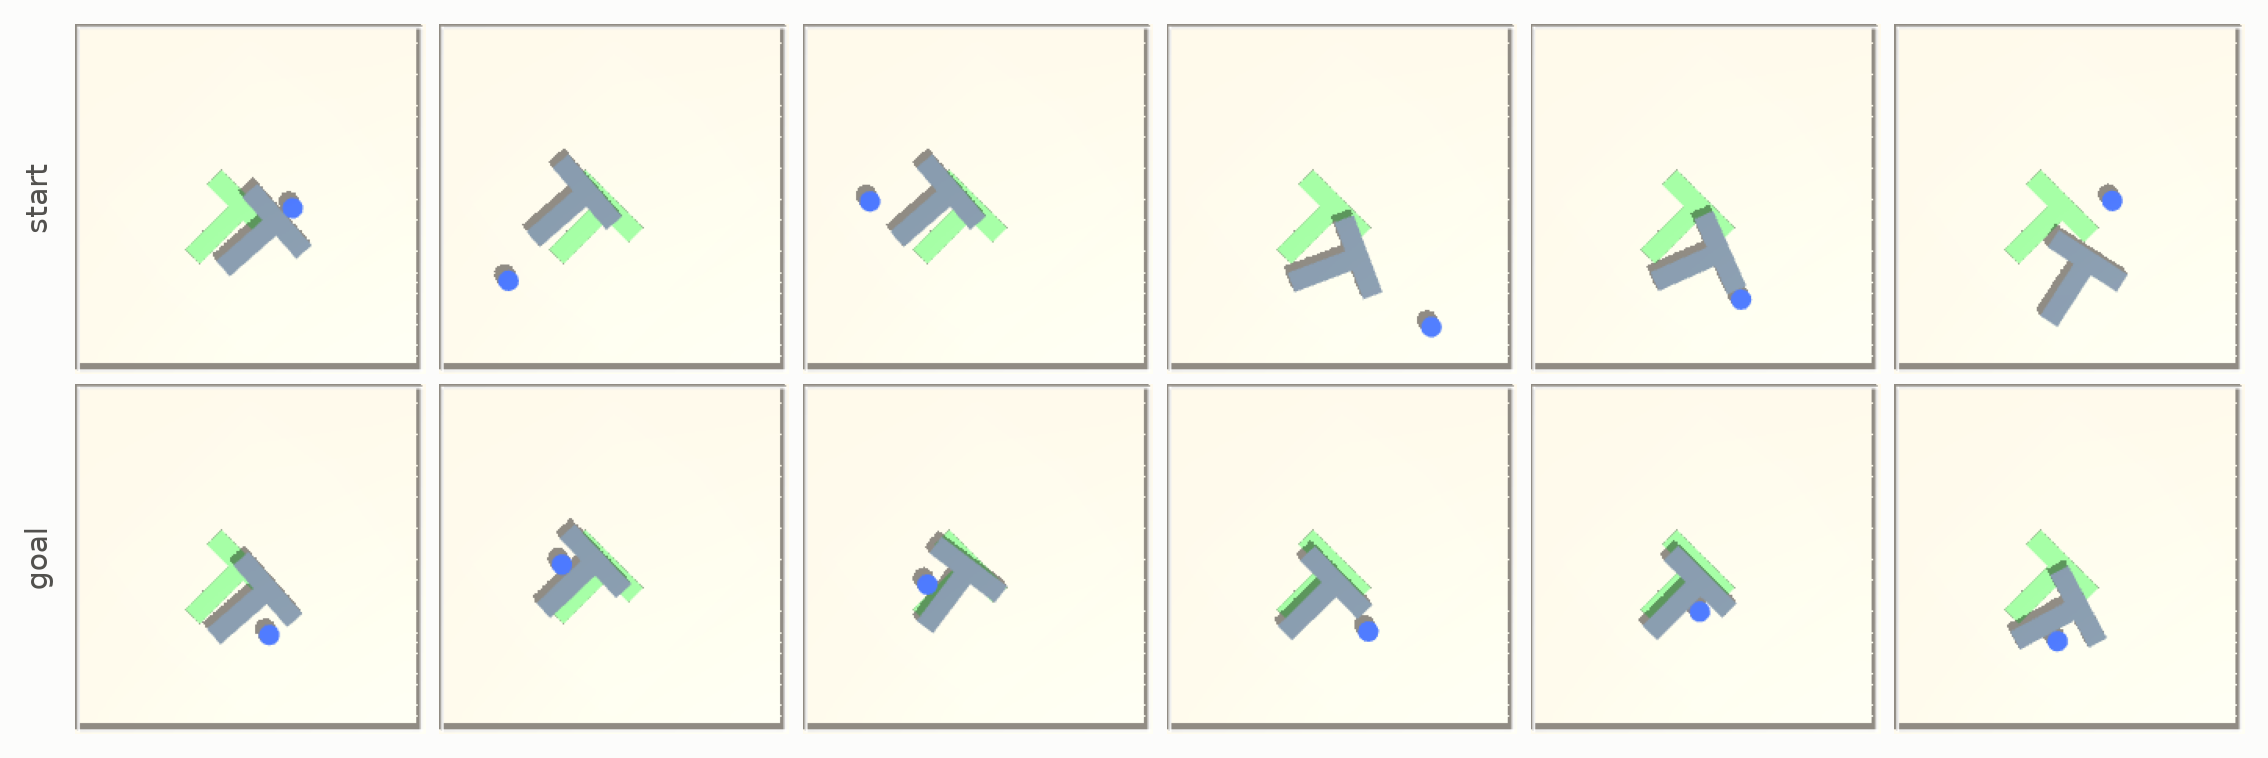

In [9]:
tasks = torch.load("checkpoints/pusht_expert_tasks.pt")  # start and goal states, (500, 7) each
env = PushT(batch_size=100, size=224)
plots.images(torch.cat([env.render(tasks["start"][:6]), env.render(tasks["goal"][:6])]).cpu(), ncols=6, size=1.5, rows=["start", "goal"])

In [10]:
CHECKPOINT = "checkpoints/lewm_pusht_mj.pt"  # the trained LeWM state dict
pt = LeWM(CLSEncoder(img_size=224, patch_size=14, embed_dim=192, depth=12, num_heads=3), action_dim=10, history=HISTORY).to(device)
pt.load_state_dict(torch.load(CHECKPOINT, map_location=device))
pt.eval()
print(f"{sum(p.numel() for p in pt.parameters()) / 1e6:.1f}M parameters")

18.0M parameters


### Evaluate with the paper's protocol
As stable-worldmodel's `eval_wm.py`: the model sees ImageNet-normalized frames and plans in the z-scored action space of its training data. CEM samples 300 plans of 5 blocks of 5 actions (one block per predicted embedding), refits to the 30 cheapest for 30 iterations, and scores each plan by the distance between its last imagined embedding and the goal's. The policy executes the whole plan, 25 steps, before planning again, and each episode gets 50 steps. As in the paper, an episode succeeds when the goal is **reached** at any step; the final-step success is shown too.

The expert data keeps the reference's action axes (pixel rows, y down), so plans flip y before they reach the env.

                          success  reached   steps  final distance  progress  smoothness  ms / step  coverage
LeWM + CEM         74% [65%, 82%]      77%    22.6         0.00332      0.78       0.331   9.48e+03       86%
random actions        0% [0%, 4%]       4%      13          0.0358         0        1.03      0.199       58%

reached the goal (paper's success): LeWM + CEM 77% [68%, 84%]   random actions 4% [2%, 10%]


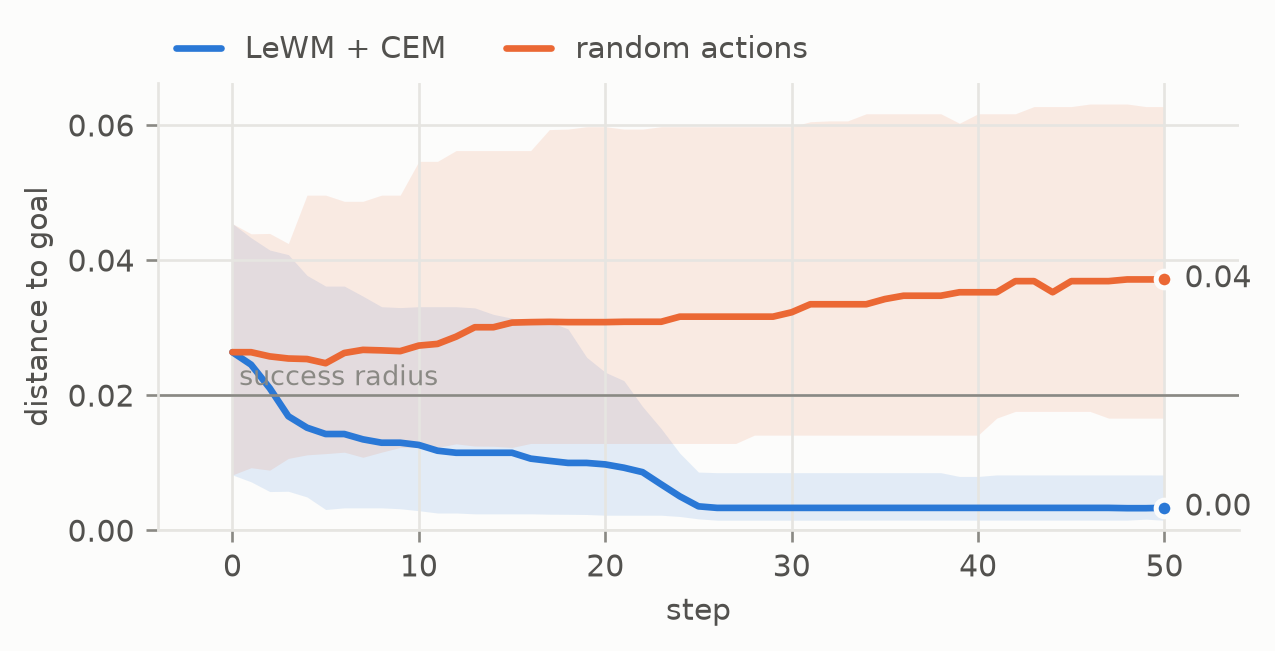

In [11]:
ACTION_MEAN, ACTION_STD = torch.tensor([-0.0078, 0.0069]), torch.tensor([0.2082, 0.2065])  # of the expert actions
FLIP_Y = torch.tensor([1.0, -1.0])
IMAGENET = torch.tensor([0.485, 0.456, 0.406], device=device).view(3, 1, 1), torch.tensor([0.229, 0.224, 0.225], device=device).view(3, 1, 1)
pt_planner = CEM(horizon=5, action_dim=10, num_samples=300, num_elites=30, iterations=30)


def embed(model, images):
    return model.encode(((images.to(device) - IMAGENET[0]) / IMAGENET[1])[:, None])


def plan_pusht(model, goal_images):
    with torch.no_grad():
        goal = embed(model, goal_images)[:, 0]

    def plan(obs):
        blocks = pt_planner(model, embed(model, obs), goal).cpu()  # (B, 5, 10), z-scored
        return ((blocks.unflatten(-1, (5, 2)) * ACTION_STD + ACTION_MEAN) * FLIP_Y).flatten(-2)

    return RecedingHorizon(plan, action_dim=2, execute=5)


start, goal_state = tasks["start"][:100], tasks["goal"][:100]
policies = {"LeWM + CEM": plan_pusht(pt, env.render(goal_state)), "random actions": evaluation.random_policy(env)}
pt_run = evaluation.goal_reaching(env, policies, start, goal_state, steps=50, record=lambda e: e.render(size=160, goal=goal_state))
pt_success = {name: metrics.success_rate(r[:, 1:].any(1)) for name, r in pt_run.reached.items()}  # the paper's measure
print(pt_run)
print("\nreached the goal (paper's success):", "   ".join(f"{name} {rate}" for name, rate in pt_success.items()))
plots.distances(pt_run.distances, radius=env.radius)

Episodes of the planner. The green T is the target drawn in every frame, as in the paper's renders; the translucent orange T marks this episode's goal (videos only):


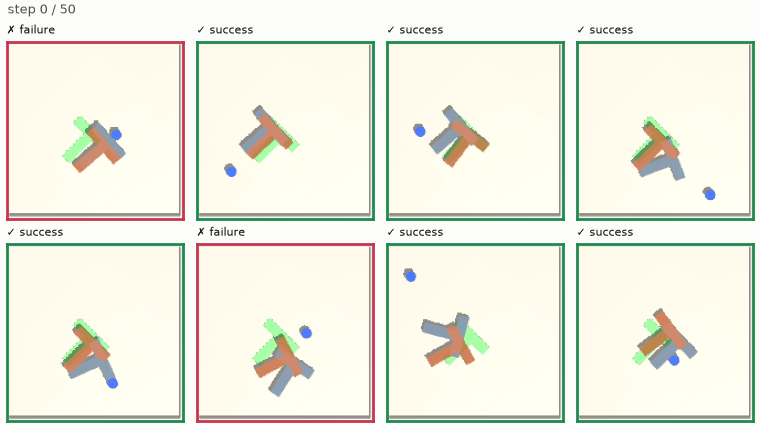

In [12]:
won = pt_run.reached["LeWM + CEM"][:, 1:].any(1)
plots.episodes(pt_run.frames["LeWM + CEM"][:8], won[:8])

Where the T went (the path darkens over time), from above:

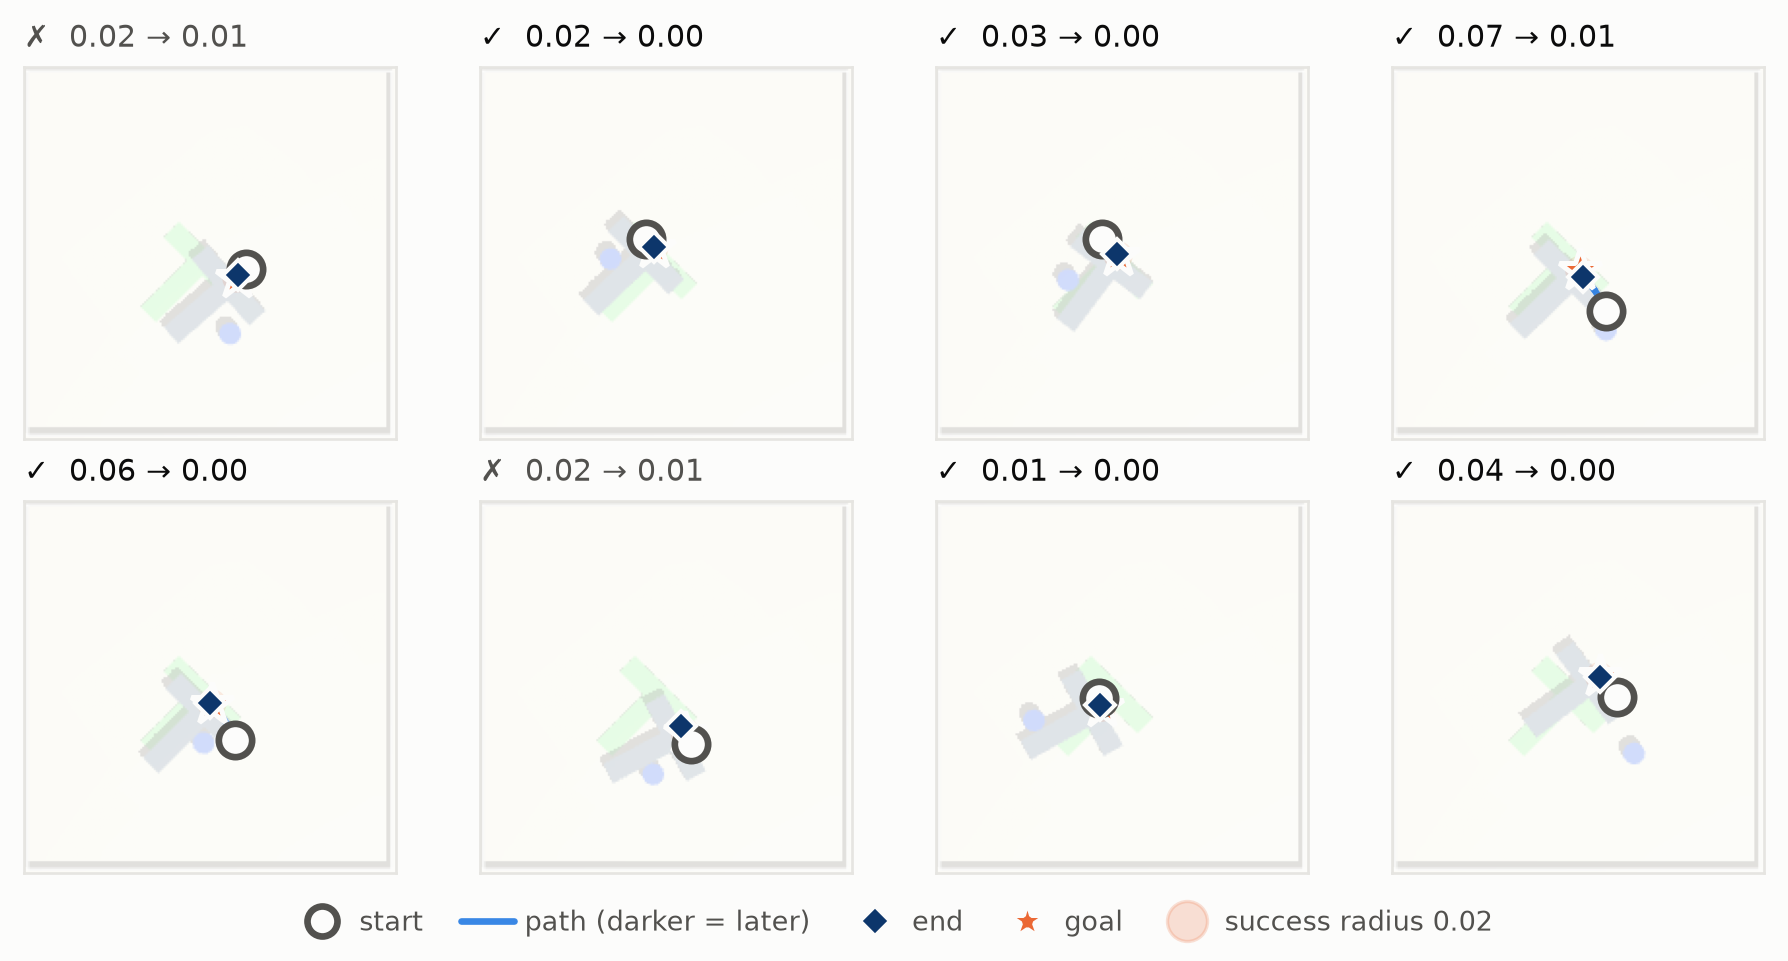

In [13]:
paths = pt_run.paths["LeWM + CEM"][:8]
plots.trajectories(env.position(paths), env.position(goal_state[:8]), radius=env.radius / env.top_size, scale=env.top_size, background=env.render(goal_state[:8], camera="top", size=192), success=won[:8])

## Summary
Arm tasks score the final step; Push-T scores reaching the goal at any step, as the paper does.

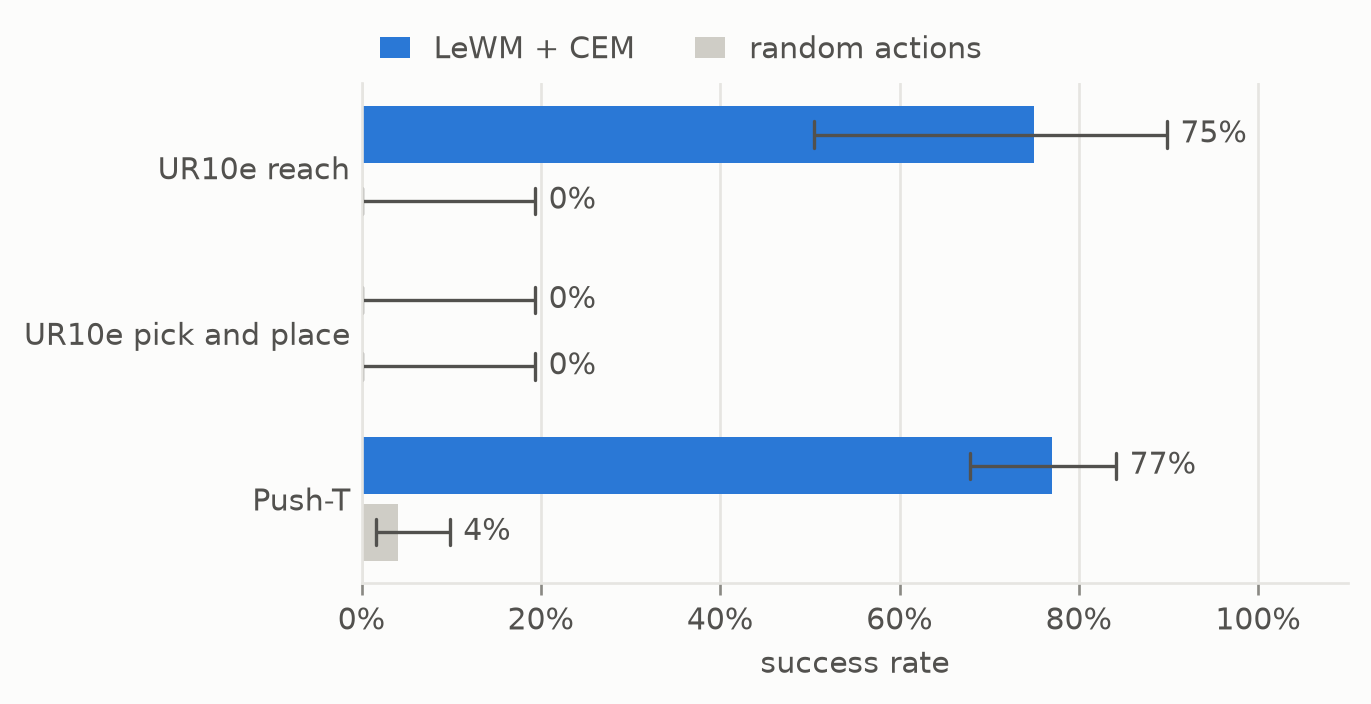

In [14]:
results = {"UR10e reach": arm_runs["reach"].intervals(), "UR10e pick and place": arm_runs["pick and place"].intervals(), "Push-T": pt_success}
plots.bars({name: {k: r[k] for k in ("LeWM + CEM", "random actions")} for name, r in results.items()}, xlabel="success rate", baseline="random actions")